# 밥심 가중치 실험

이 노트북은 **가상의 생활 상황**으로 밥솥 사용 변화 계산식의 후보 가중치를 찾습니다. 현재 결과는 `뚜껑 열림 감소 0.1 + 첫 개방 지연 0.4 + 취사·개방 불일치 0.1 + 장시간 미개방 0.4`, 기준점 `0.3`입니다. **실제 가구의 건강 위험 예측식이 아니며 Home Assistant의 라이브 규칙을 바꾸지 않습니다.**

위에서 아래로 셀을 실행하면 동일한 결과를 재현합니다. 별도 파일 업로드나 인증은 필요하지 않습니다.


## 실험 방법

정상, 취사 뒤 개방 감소, 점진적 감소, 장시간 미개방, 외출, 통신 장애, 센서 잡음을 **상황으로 먼저 생성**합니다. 정답 라벨은 상황 종류에서 정하며 찾으려는 가중치 공식으로 만들지 않습니다. 학습 시드 11에서 후보를 찾고, 다른 시드 31·47·73과 변동성에서 비교합니다. 통신 장애·외출은 판정 대상에서 제외합니다.

점수의 입력 네 가지는 개인 기준 대비 뚜껑 열림 감소, 첫 개방 지연 증가, 취사·개방 불일치, 마지막 개방 이후 시간 증가를 0~1 범위로 정리한 값입니다. 가중치 후보는 네 값의 합이 1이 되도록 탐색합니다. 기준점도 0.3~0.6에서 함께 탐색하며, F1과 오경보율을 고려해 선택합니다. 다른 Matter 기기 연계는 향후 확장 범위이며 이 노트북에서 구현·평가하지 않습니다.


## 1. 가상 생활 상황 만들기

아래 코드는 프로젝트의 `ai/synthetic.py`를 노트북 안에 포함한 것입니다.


In [1]:
"""Generate labeled situations independently from candidate score weights."""


from dataclasses import asdict, dataclass
from random import Random


SCENARIOS = ("normal", "normal", "normal", "mismatch", "gradual", "acute", "away", "communication_failure", "sensor_noise")


@dataclass(frozen=True)
class Case:
    scenario: str
    label: int | None
    open_ratio: float | None
    delay_ratio: float | None
    cook_ratio: float | None
    hours_ratio: float | None
    data_available: bool
    away: bool

    def as_dict(self) -> dict[str, object]:
        return asdict(self)


def population(seed: int, size: int = 500, *, variability: float = 0.2) -> list[Case]:
    if size < 1 or variability < 0:
        raise ValueError("invalid population settings")
    rng = Random(seed)
    cases: list[Case] = []
    for index in range(size):
        scenario = SCENARIOS[index % len(SCENARIOS)]
        def jitter(value: float) -> float:
            return max(0.0, rng.gauss(value, variability))
        open_ratio, delay_ratio, cook_ratio, hours_ratio = (
            jitter(1), jitter(1), jitter(1), jitter(1)
        )
        if scenario == "mismatch":
            open_ratio, delay_ratio, cook_ratio = jitter(0.35), jitter(2.4), jitter(1)
        elif scenario == "gradual":
            open_ratio, cook_ratio, hours_ratio = jitter(0.5), jitter(0.55), jitter(1.6)
        elif scenario == "acute":
            open_ratio, hours_ratio = jitter(0.05), jitter(3)
        elif scenario == "sensor_noise":
            open_ratio = jitter(0.1)
        cases.append(Case(
            scenario=scenario,
            label=1 if scenario in {"mismatch", "gradual", "acute"} else 0 if scenario in {"normal", "sensor_noise"} else None,
            open_ratio=open_ratio if scenario != "communication_failure" else None,
            delay_ratio=delay_ratio if scenario != "communication_failure" else None,
            cook_ratio=cook_ratio if scenario != "communication_failure" else None,
            hours_ratio=hours_ratio if scenario != "communication_failure" else None,
            data_available=scenario != "communication_failure",
            away=scenario == "away",
        ))
    rng.shuffle(cases)
    return cases


## 현재 Home Assistant 규칙 불러오기

아래 코드는 프로젝트의 개인 기준 자료형과 `RuleDetector`를 그대로 포함합니다. 가상 비율을 특징 값과 개인 기준으로 바꿔 현재 운영 규칙을 실행합니다.


In [2]:
"""Rolling, per-person baseline from eligible daily feature snapshots."""


from dataclasses import asdict, dataclass
from datetime import date, datetime, timedelta, timezone
from statistics import median
from typing import Mapping
from zoneinfo import ZoneInfo


METRICS = (
    "cook_count_24h",
    "lid_open_count_24h",
    "hours_since_last_open",
    "median_first_open_delay_min",
    "cook_interval_hours",
)


def _quantile(values: list[float], fraction: float) -> float:
    ordered = sorted(values)
    position = (len(ordered) - 1) * fraction
    left = int(position)
    weight = position - left
    return ordered[left] * (1 - weight) + ordered[min(left + 1, len(ordered) - 1)] * weight


@dataclass(frozen=True)
class MetricStats:
    median: float
    q25: float
    q75: float
    samples: int


@dataclass(frozen=True)
class BaselineSnapshot:
    device_id: str
    source: str
    as_of: str
    sample_days: int
    ready: bool
    metrics: dict[str, MetricStats]
    open_count_trend_per_day: float | None

    def as_dict(self) -> dict[str, object]:
        return asdict(self)


class PersonalBaselineEngine:
    def __init__(self, window_days: int = 14, min_days: int = 7, timezone_name: str = "Asia/Seoul") -> None:
        if window_days < 1 or min_days < 1 or min_days > window_days:
            raise ValueError("invalid baseline window")
        self.window_days = window_days
        self.min_days = min_days
        # KST has no daylight-saving transitions in the project's time range.
        # A fixed offset also works with the standard Windows Python install,
        # which does not bundle the IANA timezone database.
        self.timezone = timezone(timedelta(hours=9)) if timezone_name == "Asia/Seoul" else ZoneInfo(timezone_name)
        self._days: dict[tuple[str, str], dict[date, dict[str, float | None]]] = {}

    def dump_state(self) -> list[dict[str, object]]:
        return [
            {"source": source, "device_id": device_id, "day": day.isoformat(), "values": values}
            for (source, device_id), days in self._days.items()
            for day, values in days.items()
        ]

    def load_state(self, stored: list[dict[str, object]]) -> None:
        self._days.clear()
        for item in stored:
            source = str(item["source"])
            device_id = str(item["device_id"])
            day = date.fromisoformat(str(item["day"]))
            values = item["values"]
            if not isinstance(values, dict):
                raise ValueError("invalid stored baseline values")
            self._days.setdefault((source, device_id), {})[day] = values

    def _day(self, as_of: str) -> date:
        observed = datetime.fromisoformat(as_of.replace("Z", "+00:00"))
        if observed.tzinfo is None or observed.utcoffset() is None:
            raise ValueError("baseline time must include a timezone")
        return observed.astimezone(self.timezone).date()

    def record(self, features: Mapping[str, object], status: str) -> bool:
        """Keep one latest normal sample per local day; abnormal days are removed."""
        source = features.get("source")
        device_id = features.get("device_id")
        as_of = features.get("as_of")
        if not all(isinstance(item, str) and item for item in (source, device_id, as_of)):
            raise ValueError("features are missing source, device_id, or as_of")
        day = self._day(as_of)
        key = (source, device_id)
        samples = self._days.setdefault(key, {})
        if status == "check_required":
            samples.pop(day, None)
            return False
        if status not in {"learning", "normal"}:
            return False
        if features.get("availability") != "online" or features.get("has_data_gap"):
            return False
        numeric: dict[str, float | None] = {}
        for name in METRICS:
            value = features.get(name)
            if value is None:
                numeric[name] = None
            elif isinstance(value, (int, float)) and not isinstance(value, bool) and value >= 0:
                numeric[name] = float(value)
            else:
                raise ValueError(f"invalid feature: {name}")
        samples[day] = numeric
        cutoff = day - timedelta(days=self.window_days)
        for old in tuple(samples):
            if old < cutoff:
                del samples[old]
        return True

    def snapshot(self, source: str, device_id: str, as_of: str) -> BaselineSnapshot:
        today = self._day(as_of)
        cutoff = today - timedelta(days=self.window_days)
        # Exclude today's potentially changing observations from comparison.
        daily = {
            day: values
            for day, values in self._days.get((source, device_id), {}).items()
            if cutoff <= day < today
        }
        metrics: dict[str, MetricStats] = {}
        for name in METRICS:
            values = [value[name] for value in daily.values() if value[name] is not None]
            if values:
                metrics[name] = MetricStats(
                    median=float(median(values)),
                    q25=_quantile(values, 0.25),
                    q75=_quantile(values, 0.75),
                    samples=len(values),
                )
        open_days = sorted(
            (day, values["lid_open_count_24h"])
            for day, values in daily.items()
            if values["lid_open_count_24h"] is not None
        )
        trend = None
        if len(open_days) >= 3:
            xs = [(day - open_days[0][0]).days for day, _ in open_days]
            ys = [value for _, value in open_days]
            avg_x = sum(xs) / len(xs)
            avg_y = sum(ys) / len(ys)
            variance = sum((x - avg_x) ** 2 for x in xs)
            if variance:
                trend = sum((x - avg_x) * (y - avg_y) for x, y in zip(xs, ys)) / variance
        ready = len(daily) >= self.min_days and all(
            name in metrics and metrics[name].samples >= self.min_days
            for name in ("cook_count_24h", "lid_open_count_24h")
        )
        return BaselineSnapshot(
            device_id=device_id,
            source=source,
            as_of=as_of,
            sample_days=len(daily),
            ready=ready,
            metrics=metrics,
            open_count_trend_per_day=trend,
        )


In [3]:
"""Conservative initial rules for routine changes, prior to calibration.

These outputs describe observed cooker behavior. They do not diagnose health or
prove that someone ate a meal.
"""


from dataclasses import asdict, dataclass
from typing import Mapping



@dataclass(frozen=True)
class DetectionResult:
    device_id: str
    source: str
    as_of: str
    routine_status: str
    severity: str
    reason_codes: tuple[str, ...]
    score: float | None
    evidence: dict[str, float | None]

    def as_dict(self) -> dict[str, object]:
        result = asdict(self)
        result["reason_codes"] = list(self.reason_codes)
        return result


class RuleDetector:
    def __init__(self, threshold: float = 0.6) -> None:
        if not 0 < threshold <= 1:
            raise ValueError("threshold must be in (0, 1]")
        self.threshold = threshold

    @staticmethod
    def _number(features: Mapping[str, object], name: str) -> float | None:
        value = features.get(name)
        return float(value) if isinstance(value, (int, float)) and not isinstance(value, bool) else None

    @staticmethod
    def _ratio(value: float | None, baseline: float | None) -> float | None:
        return value / baseline if value is not None and baseline is not None and baseline > 0 else None

    def detect(
        self,
        features: Mapping[str, object],
        baseline: BaselineSnapshot,
        *,
        away: bool = False,
    ) -> DetectionResult:
        source = str(features["source"])
        device_id = str(features["device_id"])
        as_of = str(features["as_of"])

        def result(status: str, severity: str, reasons: tuple[str, ...], score: float | None = None,
                   evidence: dict[str, float | None] | None = None) -> DetectionResult:
            return DetectionResult(device_id, source, as_of, status, severity, reasons, score, evidence or {})

        if features.get("availability") != "online" or features.get("has_data_gap"):
            return result("data_unavailable", "info", ("COOKER_DATA_UNAVAILABLE",))
        if away:
            return result("away", "info", ("AWAY_DECLARED",))
        if not baseline.ready:
            return result("learning", "info", ("BASELINE_INSUFFICIENT",))

        cook = self._number(features, "cook_count_24h")
        opens = self._number(features, "lid_open_count_24h")
        hours = self._number(features, "hours_since_last_open")
        delay = self._number(features, "latest_first_open_delay_min")
        if delay is None:
            delay = self._number(features, "median_first_open_delay_min")
        cook_base = baseline.metrics.get("cook_count_24h")
        open_base = baseline.metrics.get("lid_open_count_24h")
        delay_base = baseline.metrics.get("median_first_open_delay_min")
        hours_base = baseline.metrics.get("hours_since_last_open")
        if cook is None or opens is None or cook_base is None or open_base is None:
            return result("data_unavailable", "info", ("COOKER_DATA_UNAVAILABLE",))

        cook_ratio = self._ratio(cook, cook_base.median)
        open_ratio = self._ratio(opens, open_base.median)
        delay_ratio = self._ratio(delay, delay_base.median if delay_base else None)
        pending_delay = self._number(features, "pending_first_open_delay_min")
        if pending_delay is not None:
            delay_ratio = self._ratio(pending_delay, delay_base.median if delay_base else None)
        hours_ratio = self._ratio(hours, hours_base.median if hours_base else None)
        evidence = {
            "cook_count_ratio": cook_ratio,
            "lid_open_count_ratio": open_ratio,
            "first_open_delay_ratio": delay_ratio,
            "hours_since_last_open_ratio": hours_ratio,
        }

        waiting_for_first_open = pending_delay is not None
        cooking_in_progress = features.get("cooking_in_progress") is True
        wait_is_long = delay_ratio is not None and delay_ratio >= 2
        open_drop_allowed = not cooking_in_progress and (not waiting_for_first_open or wait_is_long)
        open_drop = max(0.0, min(1.0, 1 - open_ratio)) if open_ratio is not None and open_drop_allowed else 0.0
        delay_growth = max(0.0, min(1.0, (delay_ratio - 1) / 2)) if delay_ratio is not None else 0.0
        mismatch = not cooking_in_progress and cook_ratio is not None and cook_ratio >= 0.75 and (
            (open_drop_allowed and open_ratio is not None and open_ratio <= 0.5) or wait_is_long
        )
        score = min(1.0, 0.4 * open_drop + 0.3 * delay_growth + 0.3 * float(mismatch))
        if mismatch:
            score = max(score, self.threshold)
        reasons: list[str] = []
        if mismatch:
            reasons.append("COOK_OPEN_MISMATCH")
        if open_drop_allowed and open_ratio is not None and open_ratio <= 0.5:
            reasons.append("LID_ACTIVITY_DECREASED")
        if not cooking_in_progress and wait_is_long:
            reasons.append("FIRST_OPEN_DELAY_HIGH")
        if not cooking_in_progress and opens == 0 and open_base.median >= 1 and hours is not None:
            inactivity_limit = max(24.0, (hours_base.median * 2) if hours_base else 24.0)
            if hours >= inactivity_limit:
                reasons.append("ACUTE_INACTIVITY")
                score = max(score, self.threshold)
        if (
            open_ratio is not None and cook_ratio is not None
            and open_ratio < 0.7 and cook_ratio < 0.7
            and baseline.open_count_trend_per_day is not None
            and baseline.open_count_trend_per_day <= -0.2
        ):
            reasons.append("GRADUAL_DECLINE")
            score = max(score, self.threshold)
        if reasons and score >= self.threshold:
            return result("check_required", "warning", tuple(reasons), round(score, 4), evidence)
        return result("normal", "none", (), round(score, 4), evidence)


## 2. 계산식 후보 찾기

각 비율은 **현재값 ÷ 개인의 평소 중앙값**입니다. `clip(x)`는 값을 0~1 사이로 제한합니다.

- 열림 감소 = `clip(1 − 열림 횟수 비율)`
- 지연 증가 = `clip((첫 개방 지연 비율 − 1) ÷ 2)`
- 취사·개방 불일치 = 취사 횟수 비율이 0.75 이상이면서, 열림 횟수 비율이 0.5 이하이거나 지연 비율이 2 이상이면 1, 아니면 0
- 미개방 시간 증가 = `clip((마지막 개방 이후 시간 비율 − 1) ÷ 2)`

후보 점수는 이 네 값에 각각 가중치를 곱해 더합니다. 가상 데이터에서 찾은 후보는 `0.1×열림 감소 + 0.4×지연 증가 + 0.1×불일치 + 0.4×미개방 시간 증가`이며, `점수 ≥ 0.3`이면 **가상 실험에서** 확인 필요로 분류합니다. 예를 들어 네 입력이 차례로 `0.5, 0.5, 1, 0.5`이면 점수는 `0.55`입니다.

이 실험 코드는 실제 일별 기록 대신 위 비율을 직접 생성합니다. 후보 탐색은 가중치 네 개의 합이 1인 조합과 기준점 0.3~0.6을 비교합니다. 현재 Home Assistant의 보수적 판정 규칙은 별도이며, 이 후보식을 자동 적용하지 않습니다.


In [4]:
"""Cooker-only offline grid search with independent synthetic holdouts."""


import json
from itertools import product
from pathlib import Path
from typing import Callable



def components(case: Case) -> tuple[float, float, float, float]:
    open_ratio = case.open_ratio if case.open_ratio is not None else 0.0
    delay_ratio = case.delay_ratio if case.delay_ratio is not None else 1.0
    cook_ratio = case.cook_ratio if case.cook_ratio is not None else 0.0
    hours_ratio = case.hours_ratio if case.hours_ratio is not None else 1.0
    opened = max(0.0, min(1.0, 1 - open_ratio))
    delay = max(0.0, min(1.0, (delay_ratio - 1) / 2))
    mismatch = float(cook_ratio >= 0.75 and (open_ratio <= 0.5 or delay_ratio >= 2))
    inactivity = max(0.0, min(1.0, (hours_ratio - 1) / 2))
    return opened, delay, mismatch, inactivity


def predict(case: Case, weights: tuple[float, ...], threshold: float) -> int | None:
    if case.away or not case.data_available:
        return None
    values = components(case)
    score = sum(w * v for w, v in zip(weights, values))
    return int(score >= threshold)


def _measure(cases: list[Case], predictor: Callable[[Case], int | None]) -> dict[str, float | int]:
    tp = fp = tn = fn = 0
    for case in cases:
        prediction = predictor(case)
        if case.label is None or prediction is None:
            continue
        if case.label and prediction:
            tp += 1
        elif not case.label and prediction:
            fp += 1
        elif case.label:
            fn += 1
        else:
            tn += 1
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
        "precision": round(precision, 4), "recall": round(recall, 4),
        "f1": round(2 * precision * recall / (precision + recall), 4) if precision + recall else 0.0,
        "false_positive_rate": round(fp / (fp + tn), 4) if fp + tn else 0.0,
        "false_negative_rate": round(fn / (fn + tp), 4) if fn + tp else 0.0,
    }


def metrics(cases: list[Case], weights: tuple[float, ...], threshold: float) -> dict[str, float | int]:
    return _measure(cases, lambda case: predict(case, weights, threshold))


def live_predict(case: Case) -> int | None:
    """Run the actual HA RuleDetector on a synthetic feature/baseline pair."""
    if case.away or not case.data_available:
        return None
    metrics_by_name = {
        "cook_count_24h": MetricStats(2.0, 2.0, 2.0, 7),
        "lid_open_count_24h": MetricStats(2.0, 2.0, 2.0, 7),
        "median_first_open_delay_min": MetricStats(30.0, 30.0, 30.0, 7),
        "hours_since_last_open": MetricStats(12.0, 12.0, 12.0, 7),
    }
    baseline = BaselineSnapshot(
        device_id="synthetic_cooker", source="synthetic", as_of="2026-10-02T00:00:00+00:00",
        sample_days=7, ready=True, metrics=metrics_by_name,
        open_count_trend_per_day=-0.3 if case.scenario == "gradual" else 0.0,
    )
    feature = {
        "device_id": "synthetic_cooker", "source": "synthetic", "as_of": baseline.as_of,
        "availability": "online", "has_data_gap": False,
        "cook_count_24h": round(2 * case.cook_ratio) if case.cook_ratio is not None else None,
        "lid_open_count_24h": round(2 * case.open_ratio) if case.open_ratio is not None else None,
        "hours_since_last_open": 12 * case.hours_ratio if case.hours_ratio is not None else None,
        "latest_first_open_delay_min": 30 * case.delay_ratio if case.delay_ratio is not None else None,
        "median_first_open_delay_min": 30 * case.delay_ratio if case.delay_ratio is not None else None,
    }
    result = RuleDetector().detect(feature, baseline)
    return int(result.routine_status == "check_required")


def live_metrics(cases: list[Case]) -> dict[str, float | int]:
    return _measure(cases, live_predict)


def calibrate(train: list[Case]) -> tuple[tuple[float, ...], float]:
    best: tuple[float, tuple[float, ...], float] | None = None
    for a, b, c, d in product((0.1, 0.2, 0.3, 0.4), repeat=4):
        if abs(a + b + c + d - 1) > 1e-8:
            continue
        weights = (a, b, c, d)
        for threshold in (0.3, 0.4, 0.5, 0.6):
            result = metrics(train, weights, threshold)
            objective = result["f1"] - 0.2 * result["false_positive_rate"]
            candidate = (objective, weights, threshold)
            if best is None or candidate > best:
                best = candidate
    assert best is not None
    return best[1], best[2]


def experiment() -> dict[str, object]:
    train = population(11, 1800)
    holdouts = [population(seed, 900, variability=variance)
                for seed, variance in ((31, 0.2), (47, 0.35), (73, 0.4))]
    cooker = calibrate(train)
    return {
        "scope": "Synthetic scenarios only; no claim about real household or health outcomes.",
        "scenario_labels": "Situation definitions, independent of score weights.",
        "train_seeds": [11], "holdout_seeds": [31, 47, 73],
        "variants": {
            "live_rule": {"weights": None, "threshold": None,
                          "holdouts": [live_metrics(cases) for cases in holdouts]},
            "optimized_cooker": {"weights": cooker[0], "threshold": cooker[1],
                                  "holdouts": [metrics(cases, *cooker) for cases in holdouts]},
        },
    }


## 3. 결과 확인

현재 Home Assistant의 `RuleDetector`와 밥솥 데이터만으로 찾은 후보식을 비교합니다. 합성 비율을 기준 개방·취사 2회, 첫 개방 지연 30분, 마지막 개방 12시간의 특징 값으로 바꿔 운영 규칙에 넣습니다. 점진적 감소 시나리오에는 감소 추세를 함께 제공합니다. F1은 높을수록 좋고, 오경보율은 낮을수록 좋습니다. 아래 수치는 가상 시나리오에 한정됩니다.


In [5]:
calibration_result = experiment()
variants = calibration_result["variants"]
candidate = variants["optimized_cooker"]
print("밥솥 후보 가중치:", candidate["weights"], "기준점:", candidate["threshold"])
print("보류 데이터 시드:", calibration_result["holdout_seeds"])
print("\n현재 HA 규칙 / 밥솥 후보: 시드별 F1, 오경보율")
for name in ("live_rule", "optimized_cooker"):
    scores = variants[name]["holdouts"]
    print(name, "F1", [row["f1"] for row in scores], "오경보율", [row["false_positive_rate"] for row in scores])


밥솥 후보 가중치: (0.1, 0.4, 0.1, 0.4) 기준점: 0.3
보류 데이터 시드: [31, 47, 73]

현재 HA 규칙 / 밥솥 후보: 시드별 F1, 오경보율
live_rule F1 [0.8023, 0.7348, 0.7143] 오경보율 [0.2875, 0.3175, 0.33]
optimized_cooker F1 [0.8024, 0.8097, 0.7955] 오경보율 [0.0075, 0.0475, 0.0525]


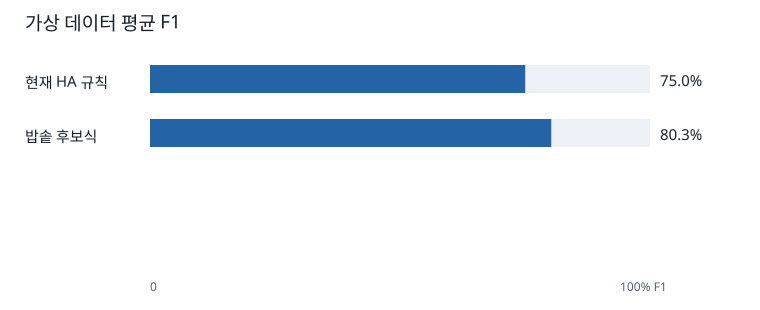

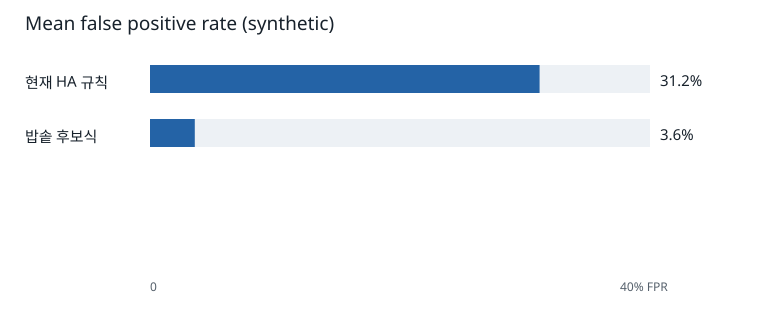

In [6]:
from html import escape
from IPython.display import SVG, display

labels = {"live_rule": "현재 HA 규칙", "optimized_cooker": "밥솥 후보식"}

def metric_chart(metric, title, axis_max, unit):
    rows = [(labels[name], sum(item[metric] for item in values["holdouts"]) / len(values["holdouts"]))
            for name, values in calibration_result["variants"].items()]
    parts = ['<svg xmlns="http://www.w3.org/2000/svg" width="760" height="310" viewBox="0 0 760 310">',
             '<rect width="760" height="310" fill="white"/>',
             f'<text x="25" y="30" font-size="19" font-family="sans-serif" fill="#17212b">{escape(title)}</text>']
    for index, (label, value) in enumerate(rows):
        y = 65 + index * 54
        width = max(0, min(500, 500 * value / axis_max))
        parts += [f'<text x="25" y="{y+23}" font-size="15" font-family="sans-serif" fill="#17212b">{escape(label)}</text>',
                  f'<rect x="150" y="{y}" width="500" height="28" fill="#edf1f5"/>',
                  f'<rect x="150" y="{y}" width="{width:.2f}" height="28" fill="#2463a6"/>',
                  f'<text x="660" y="{y+21}" font-size="15" font-family="sans-serif" fill="#17212b">{value*100:.1f}%</text>']
    parts += [f'<text x="150" y="291" font-size="12" font-family="sans-serif" fill="#55606b">0</text>',
              f'<text x="620" y="291" font-size="12" font-family="sans-serif" fill="#55606b">{axis_max*100:.0f}% {escape(unit)}</text>',
              '</svg>']
    return ''.join(parts)

f1_svg = metric_chart("f1", "가상 데이터 평균 F1", 1.0, "F1")
fpr_svg = metric_chart("false_positive_rate", "Mean false positive rate (synthetic)", 0.40, "FPR")
display(SVG(f1_svg))
display(SVG(fpr_svg))


## 해석과 한계

세 보류 시드에서 밥솥 후보의 F1은 약 0.79~0.81입니다. 이 결과는 정의한 가상 상황에서만 성립합니다. 실제 센서·생활 데이터가 모이면 오경보와 미탐을 다시 평가하고, 그 전에는 후보식을 실제 알림에 배포하지 않습니다. 타 Matter 기기 데이터는 현재 분석에 포함하지 않았습니다.


## 4. 후보 설정 저장

아래 셀은 검토용 JSON만 만듭니다. Home Assistant 설정을 변경하지 않습니다. Colab 왼쪽 파일 목록에서 다운로드할 수 있습니다.


In [7]:
model_config_candidate = {
    "schema_version": 1,
    "status": "offline_candidate_only",
    "features": ["open_drop", "delay_growth", "cook_open_mismatch", "inactivity_growth"],
    "weights": candidate["weights"][:4],
    "threshold": candidate["threshold"],
    "train_seed": 11,
    "holdout_seeds": calibration_result["holdout_seeds"],
    "warning": "Synthetic scenarios only. Do not auto-deploy to live alerts.",
}
with open("model_config_candidate.json", "w", encoding="utf-8") as file:
    json.dump(model_config_candidate, file, ensure_ascii=False, indent=2)
print("후보 설정 저장: model_config_candidate.json")


후보 설정 저장: model_config_candidate.json
